# Logistic Regression for Advertisement Classification

The decision threshold is selected on a validation split to maximize ad recall while limiting false positives (real non-ad content blocked) to at most 5%. The final test split is reserved for evaluation.

In [7]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    classification_report,
    f1_score,
    precision_score,
    recall_score,
)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

In [8]:
candidates = [
    Path.cwd() / "ml" / "dataset" / "ad.data",
    Path.cwd() / "dataset" / "ad.data",
]
dataset_path = next((path for path in candidates if path.exists()), None)
if dataset_path is None:
    raise FileNotFoundError("Could not find ml/dataset/ad.data")

df = pd.read_csv(dataset_path, header=None, skipinitialspace=True, na_values="?")
df = df.drop_duplicates().reset_index(drop=True)

X = df.iloc[:, :-1]
y = df.iloc[:, -1].astype("string").str.strip().str.rstrip(".")

print(f"Dataset shape after duplicate removal: {df.shape}")
print("Class distribution:")
print(y.value_counts())

Dataset shape after duplicate removal: (2423, 1559)
Class distribution:
1558
nonad    2037
ad        386
Name: count, dtype: Int64


In [9]:
# Reserve a stratified test split for final evaluation.
X_fit, X_test, y_fit, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

# Use a separate stratified validation split to select the decision threshold.
X_train, X_validation, y_train, y_validation = train_test_split(
    X_fit, y_fit, test_size=0.25, random_state=42, stratify=y_fit
)

print(f"Training rows: {len(X_train)}")
print(f"Validation rows: {len(X_validation)}")
print(f"Test rows: {len(X_test)}")

Training rows: 1453
Validation rows: 485
Test rows: 485


In [10]:
model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(
        class_weight="balanced",
        max_iter=2000,
        random_state=42,
    )),
])

model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('imputer', ...), ('scaler', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[object](2,)","['ad','nonad']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,1558
,"strategy strategy: str or Callable, default='mean'The imputation strategy.- If ""mean"", then replace missing values using the mean along each column. Can only be used with numeric data.- If ""median"", then replace missing values using the median along each column. Can only be used with numeric data.- If ""most_frequent"", then replace missing using the most frequent value along each column. Can be used with strings or numeric data. If there is more than one such value, only the smallest is returned.- If ""constant"", then replace missing values with fill_value. Can be used with strings or numeric data.- If an instance of Callable, then replace missing values using the scalar statistic returned by running the callable over a dense 1d array containing non-missing values of each column... versionadded:: 0.20 strategy=""constant"" for fixed value imputation... versionadded:: 1.5 strategy=callable for custom value imputation.",'median'
,"missing_values missing_values: int, float, str, np.nan, None or pandas.NA, default=np.nanThe placeholder for the missing values. All occurrences of`missing_values` will be imputed. For pandas' dataframes withnullable integer dtypes with missing values, `missing_values`can be set to either `np.nan` or `pd.NA`.",nan
,"fill_value fill_value: str or numerical value, default=NoneWhen strategy == ""constant"", `fill_value` is used to replace alloccurrences of missing_values. For string or object data types,`fill_value` must be a string.If `None`, `fill_value` will be 0 when imputing numericaldata and ""missing_value"" for strings or object data types.",None
,"copy copy: bool, default=TrueIf True, a copy of X will be created. If False, imputation willbe done in-place whenever possible. Not

In [11]:
MAX_FALSE_POSITIVE_RATE = 0.05
ad_index = list(model.classes_).index("ad")
validation_ad_probability = model.predict_proba(X_validation)[:, ad_index]
validation_binary = y_validation.eq("ad").astype(int).to_numpy()

# Test only thresholds where predictions can change, rather than a coarse grid.
candidate_thresholds = np.unique(np.concatenate(([0.0], validation_ad_probability)))
non_ad_count = int((validation_binary == 0).sum())
eligible = []

for candidate in candidate_thresholds:
    predicted_ad = (validation_ad_probability >= candidate).astype(int)
    false_positives = int(((predicted_ad == 1) & (validation_binary == 0)).sum())
    false_positive_rate = false_positives / non_ad_count
    if false_positive_rate <= MAX_FALSE_POSITIVE_RATE:
        precision = precision_score(validation_binary, predicted_ad, zero_division=0)
        recall = recall_score(validation_binary, predicted_ad, zero_division=0)
        eligible.append((candidate, false_positive_rate, precision, recall))

if not eligible:
    raise RuntimeError("No threshold satisfies the validation false-positive limit")

# Maximize ad recall while respecting the false-positive cap; use precision to break ties.
threshold, validation_fpr, validation_precision, validation_recall = max(
    eligible,
    key=lambda row: (row[3], row[2], -row[1]),
)

print(f"Selected threshold: {threshold:.6f}")
print(f"Validation false-positive rate limit: <= {MAX_FALSE_POSITIVE_RATE:.1%}")
print(f"Validation false-positive rate: {validation_fpr:.3%}")
print(f"Validation ad precision: {validation_precision:.4f}")
print(f"Validation ad recall: {validation_recall:.4f}")

Selected threshold: 0.570774
Validation false-positive rate limit: <= 5.0%
Validation false-positive rate: 4.412%
Validation ad precision: 0.7955
Validation ad recall: 0.9091


False-positive limit: <= 5.0%
Test false positives: 7 / 408
Test false-positive rate: 1.716%
Test ad precision: 0.9041
Test ad recall: 0.8571
Test ad F1-score: 0.8800
Test accuracy: 0.9629

Classification report (ad is the positive class):
              precision    recall  f1-score   support

       nonad       0.97      0.98      0.98       408
          ad       0.90      0.86      0.88        77

    accuracy                           0.96       485
   macro avg       0.94      0.92      0.93       485
weighted avg       0.96      0.96      0.96       485



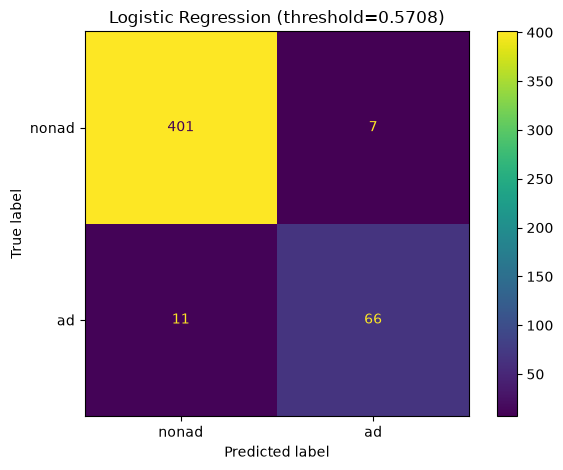

In [12]:
test_ad_probability = model.predict_proba(X_test)[:, ad_index]
y_test_binary = y_test.eq("ad").astype(int).to_numpy()
y_pred_binary = (test_ad_probability >= threshold).astype(int)

test_false_positives = int(((y_pred_binary == 1) & (y_test_binary == 0)).sum())
test_non_ad_count = int((y_test_binary == 0).sum())
test_false_positive_rate = test_false_positives / test_non_ad_count

print(f"False-positive limit: <= {MAX_FALSE_POSITIVE_RATE:.1%}")
print(f"Test false positives: {test_false_positives} / {test_non_ad_count}")
print(f"Test false-positive rate: {test_false_positive_rate:.3%}")
print(f"Test ad precision: {precision_score(y_test_binary, y_pred_binary, zero_division=0):.4f}")
print(f"Test ad recall: {recall_score(y_test_binary, y_pred_binary, zero_division=0):.4f}")
print(f"Test ad F1-score: {f1_score(y_test_binary, y_pred_binary, zero_division=0):.4f}")
print(f"Test accuracy: {accuracy_score(y_test_binary, y_pred_binary):.4f}")

print("\nClassification report (ad is the positive class):")
print(classification_report(
    y_test_binary,
    y_pred_binary,
    target_names=["nonad", "ad"],
    zero_division=0,
))

ConfusionMatrixDisplay.from_predictions(
    y_test_binary,
    y_pred_binary,
    display_labels=["nonad", "ad"],
)
plt.title(f"Logistic Regression (threshold={threshold:.4f})")
plt.tight_layout()
plt.show()